In [289]:
import pandas as pd

In [290]:
df = pd.read_csv('data/Information_skills_teachers.csv')

In [291]:
df.shape # expect (4988, 8)

(4988, 8)

In [292]:
df.head(8)

,Urbanization_level,Age,Self_efficacy,Inservice_training,Digital_activity,Gender,Information_skills,Teacher_type
0,3,45,,,0.375,1,0.000000,1
1,3,55,1,1,0.65,0,0.000000,1
2,3,34,,,0.275,0,0.498611,1
3,3,43,,,0.45,0,1.163889,1
4,3,39,0,0.2,0.25,1,0.825000,1
5,1,49,,,0.425,0,1.034722,1
6,3,33,,,0.775,0,1.090278,1
7,3,28,,,0.525,0,1.388889,1


In [293]:
df.isnull().sum() # all zeros... suspicious? keep going

Urbanization_level    0
Age                   0
Self_efficacy         0
Inservice_training    0
Digital_activity      0
Gender                0
Information_skills    0
Teacher_type          0
dtype: int64

In [294]:
df.dtypes

Urbanization_level      int64
Age                     int64
Self_efficacy             str
Inservice_training        str
Digital_activity          str
Gender                  int64
Information_skills    float64
Teacher_type            int64
dtype: object

In [295]:
repr(df['Self_efficacy'].iloc[0]) # shows ' ' (a single space)

"' '"

In [296]:
for col in ['Self_efficacy', 'Inservice_training', 'Digital_activity']:
    n_blank = df[col].str.strip().eq('').sum()
    print(f"{col}: {n_blank} blanks ({n_blank / len(df):.1%})")

Self_efficacy: 2314 blanks (46.4%)
Inservice_training: 2327 blanks (46.7%)
Digital_activity: 7 blanks (0.1%)


### What the file contains
|**Column**|Meaning (per source description)|What the file shows|Type|
|-----|-----|-----|-----|
|**Urbanization_level**|Statistical classification of the school's municipality|Values 1, 2, 3 (3 is the most common)|Ordinal category. Check the source documentation for which end is "urban"; I couldn't confirm it|
|**Age**|Teacher's age|24–66, mean ≈ 46|Numeric|
|**Self_efficacy**|Self-rated competence in work-related digital skills|0 to 1 in steps of 0.2 (six levels)|Ordinal, scaled 0–1|
|**Inservice_training**|Adequacy of in-service training in digital skills|0 to 1 in steps of 0.2|Ordinal, scaled 0–1 (higher presumably = more adequate; verify)|
|**Digital_activity**|How often digital technologies are used|0 to 0.95, ~34 distinct values|Near-continuous, scaled 0–1|
|**Gender**|Gender|	0/1; the "1" group is ≈ 24% of rows, which matches the source's "24% male", so 1 is probably male|Binary (coding inferred)|
|**Information_skills**|Sum score from the ICT skill test (retrieving, processing, sharing information)|0 to ~1.97|Continuous|
|**Teacher_type**|0 = basic education, 1 = secondary education (per source)|≈ 51% / 49%|Binary|

### Source
University of Turku, collected 2017–2019 (Zenodo record *"Information skills of Finnish basic education teachers"*). [Link to the source](https://www.kaggle.com/datasets/thedevastator/finnish-basic-education-teacher-ict-skills-and-u/discussion?sort=recent-comments)

### Messiness
*isnull()* said 0 missing, but there are actually **2314** blanks (46.4%) in *Self_efficacy*, **2327** blanks (46.7%) in *Inservice_training*, and **7** blanks (0.1%) in *Digital_activity*.

In [297]:
# Variables describing ICT skills/habits: used to BUILD the clusters
ICT_FEATURES = ['Self_efficacy', 'Digital_activity', 'Information_skills']

# Variables used afterwards to DESCRIBE who is in each cluster
PROFILE_FEATURES = ['Age', 'Gender', 'Teacher_type', 'Urbanization_level', 'Inservice_training']

In [298]:
# a. Convert hidden blanks to real missing values
for col in ['Self_efficacy', 'Inservice_training', 'Digital_activity']:
    df[col] = pd.to_numeric(df[col], errors='coerce') # blanks (spaces) become NaN

In [299]:
df.dtypes # now all numeric

Urbanization_level      int64
Age                     int64
Self_efficacy         float64
Inservice_training    float64
Digital_activity      float64
Gender                  int64
Information_skills    float64
Teacher_type            int64
dtype: object

In [300]:
missing_pct = (df.isnull().sum() / len(df) * 100).round(1)
missing_pct.sort_values(ascending=False)

Inservice_training    46.7
Self_efficacy         46.4
Digital_activity       0.1
Urbanization_level     0.0
Age                    0.0
Gender                 0.0
Information_skills     0.0
Teacher_type           0.0
dtype: float64

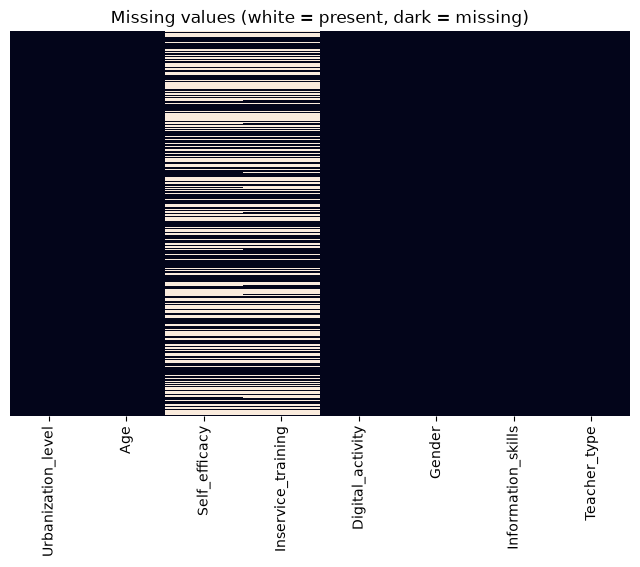

In [301]:
# b. Visualise where the missingness is
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing values (white = present, dark = missing)')
plt.savefig('missing_heatmap.png')
plt.show()

In [302]:
# c. Quantify the overlap
df[['Self_efficacy', 'Inservice_training', 'Digital_activity']]

,Self_efficacy,Inservice_training,Digital_activity
0,NaN,NaN,0.375
1,1.0,1.0,0.650
2,NaN,NaN,0.275
3,NaN,NaN,0.450
4,0.0,0.2,0.250
...,...,...,...
4983,1.0,1.0,0.600
4984,1.0,1.0,0.675
4985,1.0,0.0,0.550
4986,NaN,NaN,0.650


In [303]:
# d. Are the rows with missing values different from the rest? Rondom or not?
df['Survey_items_missing'] = df['Self_efficacy'].isnull() & df['Inservice_training'].isnull()

df.groupby('Survey_items_missing')[
    ['Age', 'Information_skills', 'Digital_activity', 'Gender', 'Teacher_type', 'Urbanization_level']
].mean().round(2)

,Age,Information_skills,Digital_activity,Gender,Teacher_type,Urbanization_level
Survey_items_missing,,,,,,
False,45.17,1.30,0.48,0.25,0.49,2.51
True,47.13,1.16,0.47,0.23,0.48,2.46


In [304]:
# e. Duplicates
df.duplicated().sum()

np.int64(29)

In [305]:
df[df.duplicated(keep=False)].sort_values(list(df.columns[:8])).head(10)

,Urbanization_level,Age,Self_efficacy,Inservice_training,Digital_activity,Gender,Information_skills,Teacher_type,Survey_items_missing
3017,1,32,NaN,NaN,0.250,0,1.294444,1,True
3018,1,32,NaN,NaN,0.250,0,1.294444,1,True
217,2,33,NaN,NaN,0.525,0,1.416667,0,True
4933,2,33,NaN,NaN,0.525,0,1.416667,0,True
1420,2,43,NaN,NaN,0.525,0,1.375000,0,True
1422,2,43,NaN,NaN,0.525,0,1.375000,0,True
2477,2,44,1.0,0.8,0.450,1,1.236111,1,False
2478,2,44,1.0,0.8,0.450,1,1.236111,1,False
4157,3,29,1.0,0.6,0.375,0,1.569444,1,False
4158,3,29,1.0,0.6,0.375,0,1.569444,1,False


In [306]:
# f. Impossible or suspicious values
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Urbanization_level,4988.0,2.488372,0.749617,1.0,2.000000,3.000000,3.000000,3.000000
Age,4988.0,46.064755,9.490110,24.0,39.000000,46.000000,53.000000,66.000000
Self_efficacy,2674.0,0.611144,0.368264,0.0,0.200000,0.600000,1.000000,1.000000
Inservice_training,2661.0,0.351672,0.377758,0.0,0.000000,0.200000,0.600000,1.000000
Digital_activity,4981.0,0.474242,0.106746,0.0,0.400000,0.475000,0.550000,0.950000
Gender,4988.0,0.241780,0.428205,0.0,0.000000,0.000000,0.000000,1.000000
Information_skills,4988.0,1.235363,0.340431,0.0,1.041667,1.284722,1.472222,1.972222
Teacher_type,4988.0,0.485766,0.499847,0.0,0.000000,0.000000,1.000000,1.000000


In [307]:
(df['Information_skills'] == 0).sum() # 0 is impossible for this variable

np.int64(9)

In [ ]:
# Cleaning up the dataset and a reason for each decision
